# 01 · Datos y descriptivos

Une las 20 features acústicas CORE con las etiquetas clínicas y arma la tabla de desarrollo para el modelado.

- Tareas: PREGUNTA1 (lo mejor que te ha pasado) y PREGUNTA2 (lo peor).
- Análisis por sexo (`SEXO` 1 = mujer, 2 = hombre).
- Valores extremos: percentiles 1–99 por sexo y tarea; `pausa_media` sin corte; `vel_articulacion` con tope de 12 vocales/s.
- DELTA = PREGUNTA2 − PREGUNTA1.
- Desenlaces: depresión = PHQ-9 ≥ 10; ansiedad = GAD-7 ≥ 10.
- La prueba final (`prueba_final_ids.csv`, 89 sujetos) se excluye antes de leer las etiquetas.
- Solo se muestran conteos y estadísticos agregados.

Salidas: `outputs/desarrollo.csv` y `outputs/limites_outliers.csv`.

## Housekeeping

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

%matplotlib inline

In [2]:
# Rutas
FEATURES_CSV = Path("../feature-extraction-UA/outputs/features_core_completos.csv")
ETIQUETAS_XLSX = Path("../baseDatos_tabular.xlsx")
PRUEBA_FINAL = Path("prueba_final_ids.csv")
SALIDAS = Path("outputs")
SALIDAS.mkdir(exist_ok=True)

# Parámetros
TAREAS = ["PREGUNTA1", "PREGUNTA2"]
SEXOS = {1: "mujer", 2: "hombre"}
OBJETIVOS = {"dep": "Depresión (PHQ-9 ≥ 10)", "ans": "Ansiedad (GAD-7 ≥ 10)"}
P_INF, P_SUP = 0.01, 0.99                # 98 % central
TRATAMIENTO = "recortar"                 # "recortar" (al límite) o "eliminar" (a faltante)
SIN_TRATAR = ["pause_mean_s"]            # sin corte
TOPE_VEL_ARTICULACION = 12               # vocales/s

FEATURES = [
    "F0semitoneFrom27.5Hz_sma3nz_amean", "F0semitoneFrom27.5Hz_sma3nz_stddevNorm",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2", "jitterLocal_sma3nz_amean", "shimmerLocaldB_sma3nz_amean",
    "HNRdBACF_sma3nz_amean", "vw_a_f1_hz_mean", "vw_a_f2_hz_mean", "loudness_sma3_stddevNorm",
    "alphaRatioV_sma3nz_amean", "hammarbergIndexV_sma3nz_amean", "slopeV0-500_sma3nz_amean",
    "mfcc1V_sma3nz_amean", "mfcc2V_sma3nz_amean", "mfcc3V_sma3nz_amean", "mfcc4V_sma3nz_amean",
    "MeanVoicedSegmentLengthSec", "pause_time_ratio", "pause_mean_s", "articulation_rate_vps",
]
# Nombres cortos
CORTO = {
    "F0semitoneFrom27.5Hz_sma3nz_amean": "F0_media", "F0semitoneFrom27.5Hz_sma3nz_stddevNorm": "F0_var",
    "F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2": "F0_rango", "jitterLocal_sma3nz_amean": "jitter",
    "shimmerLocaldB_sma3nz_amean": "shimmer", "HNRdBACF_sma3nz_amean": "HNR", "vw_a_f1_hz_mean": "F1_a",
    "vw_a_f2_hz_mean": "F2_a", "loudness_sma3_stddevNorm": "loudness_var", "alphaRatioV_sma3nz_amean": "alpha_ratio",
    "hammarbergIndexV_sma3nz_amean": "hammarberg", "slopeV0-500_sma3nz_amean": "slope_0_500",
    "mfcc1V_sma3nz_amean": "mfcc1", "mfcc2V_sma3nz_amean": "mfcc2", "mfcc3V_sma3nz_amean": "mfcc3",
    "mfcc4V_sma3nz_amean": "mfcc4", "MeanVoicedSegmentLengthSec": "seg_sonoro", "pause_time_ratio": "pausa_ratio",
    "pause_mean_s": "pausa_media", "articulation_rate_vps": "vel_articulacion",
}
NOMBRES = [CORTO[f] for f in FEATURES]

## 1. Features acústicas

PREGUNTA1 y PREGUNTA2 de los sujetos con las 4 tareas extraídas.

In [3]:
feat = pd.read_csv(FEATURES_CSV, dtype={"participant_id": str})
print(f"Archivo: {feat.shape[0]} filas | {feat['participant_id'].nunique()} sujetos | tareas: {feat['task'].value_counts().to_dict()}")
feat = feat[feat["task"].isin(TAREAS)].copy()
print(f"Solo {TAREAS}: {feat.shape[0]} filas")
print("Estados:", feat["estado"].value_counts().to_dict())

# Excluir la prueba final
prueba = pd.read_csv(PRUEBA_FINAL, dtype={"participant_id": str})["participant_id"]
en_prueba = feat["participant_id"].isin(prueba)
print(f"\nPrueba final: {prueba.nunique()} IDs, {feat.loc[en_prueba, 'participant_id'].nunique()} con features")
feat = feat[~en_prueba].copy()
print(f"Desarrollo: {feat['participant_id'].nunique()} sujetos")

Archivo: 1780 filas | 445 sujetos | tareas: {'DESCRIPCION': 445, 'PREGUNTA1': 445, 'PREGUNTA2': 445, 'TEXTO_EL_ABUELO': 445}
Solo ['PREGUNTA1', 'PREGUNTA2']: 890 filas
Estados: {'ok': 890}

Prueba final: 89 IDs, 89 con features
Desarrollo: 356 sujetos


Faltantes por feature y tarea:

In [4]:
faltantes = feat.groupby("task")[FEATURES].apply(lambda g: g.isna().sum()).T.rename(index=CORTO)
display(faltantes[faltantes.sum(axis=1) > 0])
print("Features sin faltantes:", int((faltantes.sum(axis=1) == 0).sum()), "de", len(FEATURES))

task,PREGUNTA1,PREGUNTA2
F1_a,2,2
F2_a,2,2
vel_articulacion,1,2


Features sin faltantes: 17 de 20


Tasa de muestreo y duración:

In [5]:
display(pd.crosstab(feat["tasa_muestreo_hz"], feat["task"], margins=True))
tasas = feat.pivot(index="participant_id", columns="task", values="tasa_muestreo_hz")
print(f"Sujetos con la misma tasa de muestreo en las dos tareas: {(tasas['PREGUNTA1'] == tasas['PREGUNTA2']).sum()} de {len(tasas)}")
print("Duración (s) por tarea:")
display(feat.groupby("task")["duracion_s"].describe().round(1))

task,PREGUNTA1,PREGUNTA2,All
tasa_muestreo_hz,,,
22050.0,41,41,82
44100.0,255,255,510
48000.0,55,55,110
64000.0,5,5,10
All,356,356,712


Sujetos con la misma tasa de muestreo en las dos tareas: 356 de 356
Duración (s) por tarea:


,count,mean,std,min,25%,50%,75%,max
task,,,,,,,,
PREGUNTA1,356.0,94.2,48.4,9.3,55.5,101.3,125.3,438.6
PREGUNTA2,356.0,98.4,50.1,12.1,59.4,108.9,125.9,508.3


## 2. Etiquetas y sexo

`cualestucodigo` se enlaza con `participant_id`. Se excluye `SEXO` distinto de 1 o 2.

In [6]:
etq = pd.read_excel(ETIQUETAS_XLSX)
etq["participant_id"] = etq["cualestucodigo"].astype(int).astype(str).str.zfill(3)
etq = etq[["participant_id", "SEXO", "EDAD", "TOTALPHQ9", "TOTALGAD7"]]

ids = pd.Series(feat["participant_id"].unique(), name="participant_id")
print(f"Sujetos de desarrollo sin fila en el Excel: {(~ids.isin(etq['participant_id'])).sum()}")

etq = etq[etq["participant_id"].isin(ids)].copy()
etq["dep"] = (etq["TOTALPHQ9"] >= 10).astype(int)
etq["ans"] = (etq["TOTALGAD7"] >= 10).astype(int)
etq["sexo"] = etq["SEXO"].map(SEXOS)
print("SEXO en el Excel:", etq["SEXO"].value_counts().sort_index().to_dict())
print(f"Sin SEXO = 1 o 2 (quedan fuera): {etq['sexo'].isna().sum()}")
etq = etq[etq["sexo"].notna()].copy()
print("Sujetos por sexo:", etq["sexo"].value_counts().to_dict())
print(f"EDAD faltante: {etq['EDAD'].isna().sum()} de {len(etq)}")

Sujetos de desarrollo sin fila en el Excel: 0
SEXO en el Excel: {1: 197, 2: 158, 3: 1}
Sin SEXO = 1 o 2 (quedan fuera): 1
Sujetos por sexo: {'mujer': 197, 'hombre': 158}
EDAD faltante: 73 de 355


## 3. Tabla ancha

Una fila por sujeto: `<feature>__PREGUNTA1`, `<feature>__PREGUNTA2`, tasa de muestreo y duración.

In [7]:
ancha = feat.pivot(index="participant_id", columns="task", values=FEATURES)
ancha.columns = [f"{f}__{t}" for f, t in ancha.columns]
tasa = feat.pivot(index="participant_id", columns="task", values="tasa_muestreo_hz")
tasa.columns = [f"tasa__{t}" for t in tasa.columns]
dur = feat.pivot(index="participant_id", columns="task", values="duracion_s")
dur.columns = [f"duracion__{t}" for t in dur.columns]

datos = (etq.set_index("participant_id")
         .join(ancha, how="inner").join(tasa).join(dur)
         .reset_index())
NIVELES = [f"{f}__{t}" for f in FEATURES for t in TAREAS]
print(f"Tabla de análisis: {datos.shape[0]} sujetos × {datos.shape[1]} columnas")

Tabla de análisis: 355 sujetos × 52 columnas


## 4. Prevalencias por sexo

In [8]:
filas = []
for s, g in [(s, datos[datos["sexo"] == s]) for s in SEXOS.values()] + [("total", datos)]:
    filas.append({"sexo": s, "n": len(g), "dep": g["dep"].sum(), "ans": g["ans"].sum(),
                  "ambas": (g["dep"] & g["ans"]).sum(), "ninguna": ((g["dep"] == 0) & (g["ans"] == 0)).sum()})
prev = pd.DataFrame(filas).set_index("sexo")
prev["prev_dep"] = (prev["dep"] / prev["n"]).round(3)
prev["prev_ans"] = (prev["ans"] / prev["n"]).round(3)
display(prev)
print("Correlación de Spearman PHQ-9 – GAD-7 por sexo:",
      datos.groupby("sexo").apply(lambda g: round(g["TOTALPHQ9"].corr(g["TOTALGAD7"], method="spearman"), 3)).to_dict())

,n,dep,ans,ambas,ninguna,prev_dep,prev_ans
sexo,,,,,,,
mujer,197,97,70,64,94,0.492,0.355
hombre,158,42,35,29,110,0.266,0.222
total,355,139,105,93,204,0.392,0.296


Correlación de Spearman PHQ-9 – GAD-7 por sexo: {'hombre': 0.808, 'mujer': 0.874}


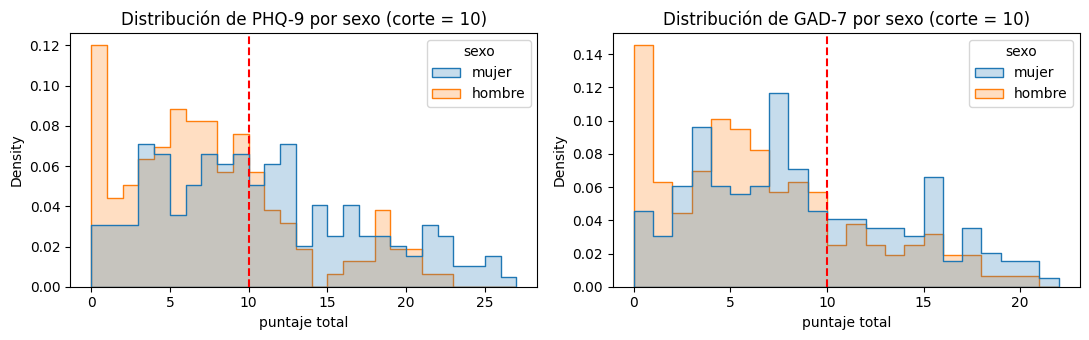

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, col, nombre in zip(ax, ["TOTALPHQ9", "TOTALGAD7"], ["PHQ-9", "GAD-7"]):
    sns.histplot(data=datos, x=col, hue="sexo", hue_order=list(SEXOS.values()), bins=range(0, int(datos[col].max()) + 2),
                 element="step", stat="density", common_norm=False, ax=a)
    a.axvline(10, color="red", ls="--")
    a.set_title(f"Distribución de {nombre} por sexo (corte = 10)"); a.set_xlabel("puntaje total")
plt.tight_layout(); plt.show()

## 5. Valores extremos

Mínimo, percentiles 1, 50 y 99 y máximo por sexo (ambas tareas), antes del tratamiento:

In [10]:
largo = feat.merge(datos[["participant_id", "sexo"]], on="participant_id")
resumen = largo.groupby("sexo")[FEATURES].quantile([0, 0.01, 0.5, 0.99, 1]).rename(columns=CORTO)
resumen.index = resumen.index.set_levels(["mín", "p1", "p50", "p99", "máx"], level=1)
display(resumen.T[list(SEXOS.values())].round(3))

sexo                 mujer                                            hombre                                        
                       mín        p1       p50       p99       máx       mín        p1       p50       p99       máx
F0_media            24.369    28.120    35.017    38.785    40.211    18.279    19.213    24.401    35.685    38.142
F0_var               0.035     0.055     0.121     0.257     0.316     0.053     0.061     0.124     0.226     0.272
F0_rango             1.179     1.415     2.935    13.066    19.796     1.306     1.555     3.156     7.664    16.357
jitter               0.013     0.016     0.028     0.072     0.084     0.017     0.020     0.036     0.074     0.079
shimmer              0.629     0.702     1.009     1.484     2.840     0.802     0.931     1.310     1.899     2.011
HNR                  0.846     3.339     8.778    12.074    13.234    -3.521    -3.211     3.836    10.285    11.361
F1_a               441.348   505.624   673.140   846.952   878.250   374.343   455.420   556.467   716.028   849.901
F2_a              1370.776  1406.851  1681.095  1870.879  1892.388  1231.815  1268.058  1456.454  1688.336  1735.103
loudness_var         0.328     0.451     0.737     1.367     1.624     0.419     0.502     0.788     1.337     1.471
alpha_ratio        -28.940   -25.581   -19.565   -13.017   -11.991   -27.241   -26.411   -19.183   -13.432   -12.481
hammarberg          20.195    21.298    29.122    36.043    40.504    20.110    21.555    28.020    36.297    39.624
slope_0_500         -0.092    -0.067    -0.008     0.046     0.049    -0.079    -0.070    -0.023     0.030     0.037
mfcc1               18.818    23.274    31.260    37.534    38.542    22.349    25.447    32.799    39.316    41.095
mfcc2               -7.653    -2.783     9.589    21.405    23.332    -4.010    -3.317    10.728    21.187    22.596
mfcc3                2.430     4.024    13.589    23.764    24.821    -1.307     4.153    17.577    29.857    31.691
mfcc4              -26.549   -21.598    -7.699     8.685    15.401   -20.773   -11.888     4.880    18.051    19.217
seg_sonoro           0.040     0.130     0.272     0.404     0.464     0.104     0.131     0.278     0.479     0.561
pausa_ratio          0.125     0.172     0.369     0.911     0.982     0.071     0.153     0.409     0.846     0.929
pausa_media          0.418     0.497     0.823     4.468    10.787     0.362     0.445     0.901     4.584     7.923
vel_articulacion     0.533     1.522     5.205    18.243   216.146     0.788     2.464     5.579    15.136    23.874

Tratamiento por sexo, tarea y feature:

- Fuera de los percentiles 1–99: el valor pasa al límite más cercano.
- `pausa_media`: sin corte.
- `vel_articulacion`: límite superior = mín(percentil 99, 12 vocales/s).

In [11]:
crudos = datos.copy()
fuera = pd.DataFrame(False, index=datos.index, columns=NIVELES)
filas = []
for s in SEXOS.values():
    m = crudos["sexo"] == s
    for c in NIVELES:
        feature = c.split("__")[0]
        if feature in SIN_TRATAR:
            lo, hi = -np.inf, np.inf
        else:
            lo, hi = crudos.loc[m, c].quantile([P_INF, P_SUP])
            if feature == "articulation_rate_vps":
                hi = min(hi, TOPE_VEL_ARTICULACION)
        fuera.loc[m, c] = (crudos.loc[m, c] < lo) | (crudos.loc[m, c] > hi)
        filas.append({"sexo": s, "columna": c, "p_inf": lo, "p_sup": hi, "n_fuera": int(fuera.loc[m, c].sum())})
        if TRATAMIENTO == "recortar":
            datos.loc[m, c] = crudos.loc[m, c].clip(lo, hi)
        elif TRATAMIENTO == "eliminar":
            datos.loc[m & fuera[c], c] = np.nan
        else:
            raise ValueError("TRATAMIENTO debe ser 'recortar' o 'eliminar'")
limites = pd.DataFrame(filas).assign(tratamiento=TRATAMIENTO)

print(f"Tratamiento: {TRATAMIENTO} | percentiles {P_INF:.0%} y {P_SUP:.0%} | sin tratar: {[CORTO[f] for f in SIN_TRATAR]} | tope de vel_articulacion: {TOPE_VEL_ARTICULACION} vocales/s")
for s in SEXOS.values():
    m = crudos["sexo"] == s
    f_s = fuera[m]
    print(f"{s} (n = {m.sum()}): {int(f_s.values.sum())} valores fuera de {int(crudos.loc[m, NIVELES].notna().values.sum())} "
          f"({f_s.values.sum() / crudos.loc[m, NIVELES].notna().values.sum():.1%}) | por columna: {f_s.sum().min()} a {f_s.sum().max()}")
    print(f"   sujetos con al menos 1 valor fuera: {int(f_s.any(axis=1).sum())} ({f_s.any(axis=1).mean():.1%}) | "
          f"con 3 o más: {int((f_s.sum(axis=1) >= 3).sum())}")
    for t in TAREAS:
        print(f"   {t}: sujetos con al menos 1 valor fuera entre las 20 features: {int(f_s[[f'{f}__{t}' for f in FEATURES]].any(axis=1).sum())}")

Tratamiento: recortar | percentiles 1% y 99% | sin tratar: ['pausa_media'] | tope de vel_articulacion: 12 vocales/s
mujer (n = 197): 153 valores fuera de 7869 (1.9%) | por columna: 0 a 5
   sujetos con al menos 1 valor fuera: 68 (34.5%) | con 3 o más: 17
   PREGUNTA1: sujetos con al menos 1 valor fuera entre las 20 features: 43
   PREGUNTA2: sujetos con al menos 1 valor fuera entre las 20 features: 46
hombre (n = 158): 154 valores fuera de 6320 (2.4%) | por columna: 0 a 6
   sujetos con al menos 1 valor fuera: 65 (41.1%) | con 3 o más: 18
   PREGUNTA1: sujetos con al menos 1 valor fuera entre las 20 features: 43
   PREGUNTA2: sujetos con al menos 1 valor fuera entre las 20 features: 49


Mayor |z| (DE desde la media del grupo), antes y después del tratamiento:

In [12]:
def z_max(tabla):
    z = tabla.groupby("sexo")[NIVELES].transform(lambda v: (v - v.mean()) / v.std()).abs().max()
    return pd.Series({CORTO[f]: max(z[f"{f}__{t}"] for t in TAREAS) for f in FEATURES})

extremos = pd.DataFrame({"|z| máx. antes": z_max(crudos), "|z| máx. después": z_max(datos)})
display(extremos.sort_values("|z| máx. antes", ascending=False).round(1))

# Valores sobre umbrales de plausibilidad
for f, umbral, unidad in [("articulation_rate_vps", 12, "vocales/s"), ("pause_mean_s", 3, "s")]:
    cols_f = [f"{f}__{t}" for t in TAREAS]
    lim = limites.loc[limites["columna"].isin(cols_f), "p_sup"]
    texto_lim = "sin corte" if np.isinf(lim).all() else f"entre {lim.min():.1f} y {lim.max():.1f}"
    print(f"{CORTO[f]} > {umbral} {unidad}: {int((crudos[cols_f] > umbral).values.sum())} valores antes | "
          f"{int((datos[cols_f] > umbral).values.sum())} después | límite superior aplicado: {texto_lim}")

,|z| máx. antes,|z| máx. después
vel_articulacion,11.4,5.2
pausa_media,11.0,11.0
shimmer,9.6,3.3
F0_rango,8.4,4.6
jitter,5.0,4.3
F0_media,4.8,4.1
F1_a,4.6,2.7
seg_sonoro,4.4,2.9
F0_var,4.4,3.3
loudness_var,4.4,3.8


vel_articulacion > 12 vocales/s: 11 valores antes | 0 después | límite superior aplicado: entre 11.6 y 12.0
pausa_media > 3 s: 19 valores antes | 19 después | límite superior aplicado: sin corte


## 6. DELTA = PREGUNTA2 − PREGUNTA1

Con los valores ya tratados, por feature y sexo:

- `r_P1_P2`: correlación de Pearson entre tareas. Si es alta, la feature describe sobre todo al hablante. (resulta que el delta efectivamente no funciona mucho, pero lo deje para que sepa que probe la idea)
- `dz`: media del DELTA / DE del DELTA.
- `q_BH`: p de la prueba t pareada, corregido por BH (20 pruebas por sexo).

In [13]:
for f in FEATURES:
    datos[f"{f}__DELTA"] = datos[f"{f}__PREGUNTA2"] - datos[f"{f}__PREGUNTA1"]
CONJUNTOS = TAREAS + ["DELTA"]

filas = []
for s in SEXOS.values():
    g = datos[datos["sexo"] == s]
    for f in FEATURES:
        par = g[[f"{f}__PREGUNTA1", f"{f}__PREGUNTA2"]].dropna()
        a, b = par.iloc[:, 0], par.iloc[:, 1]
        d = b - a
        filas.append({"sexo": s, "feature": CORTO[f], "n": len(par), "r_P1_P2": a.corr(b), "delta_media": d.mean(),
                      "delta_DE": d.std(), "dz": d.mean() / d.std(), "p": stats.ttest_rel(b, a).pvalue})
cambio = pd.DataFrame(filas)
cambio["q_BH"] = cambio.groupby("sexo")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
display(cambio.pivot(index="feature", columns="sexo", values=["r_P1_P2", "dz", "q_BH"])
        .loc[NOMBRES].reindex(columns=list(SEXOS.values()), level=1).round(3))
for s in SEXOS.values():
    c = cambio[cambio["sexo"] == s]
    print(f"{s}: r entre {c['r_P1_P2'].min():.2f} y {c['r_P1_P2'].max():.2f} (mediana {c['r_P1_P2'].median():.2f}) | "
          f"|dz| máx. {c['dz'].abs().max():.2f} | q_BH < 0,05 en {(c['q_BH'] < 0.05).sum()} de {len(c)} | n con DELTA: {c['n'].min()} a {c['n'].max()}")

r_P1_P2            dz          q_BH       
sexo               mujer hombre  mujer hombre  mujer hombre
feature                                                    
F0_media           0.907  0.945 -0.093 -0.305  0.379  0.004
F0_var             0.726  0.692 -0.032 -0.012  0.767  0.884
F0_rango           0.751  0.709 -0.050 -0.044  0.695  0.626
jitter             0.820  0.755  0.174  0.149  0.072  0.209
shimmer            0.807  0.857  0.178  0.106  0.072  0.371
HNR                0.898  0.924 -0.170 -0.227  0.072  0.033
F1_a               0.844  0.816 -0.003  0.061  0.971  0.626
F2_a               0.799  0.796 -0.219 -0.049  0.026  0.626
loudness_var       0.861  0.851 -0.240 -0.143  0.019  0.214
alpha_ratio        0.845  0.852 -0.042 -0.057  0.695  0.626
hammarberg         0.824  0.833  0.090  0.156  0.379  0.209
slope_0_500        0.919  0.923 -0.116 -0.134  0.234  0.234
mfcc1              0.905  0.913  0.147  0.045  0.116  0.626
mfcc2              0.858  0.902 -0.023  0.069  0.785  0.626
mfcc3              0.833  0.883 -0.023 -0.253  0.785  0.018
mfcc4              0.912  0.921  0.151  0.075  0.116  0.626
seg_sonoro         0.674  0.730 -0.129 -0.054  0.178  0.626
pausa_ratio        0.714  0.685 -0.065  0.125  0.607  0.259
pausa_media        0.349  0.652 -0.044  0.167  0.695  0.189
vel_articulacion   0.713  0.594  0.055  0.042  0.685  0.626

mujer: r entre 0.35 y 0.92 (mediana 0.83) | |dz| máx. 0.24 | q_BH < 0,05 en 2 de 20 | n con DELTA: 194 a 197
hombre: r entre 0.59 y 0.94 (mediana 0.84) | |dz| máx. 0.30 | q_BH < 0,05 en 3 de 20 | n con DELTA: 158 a 158


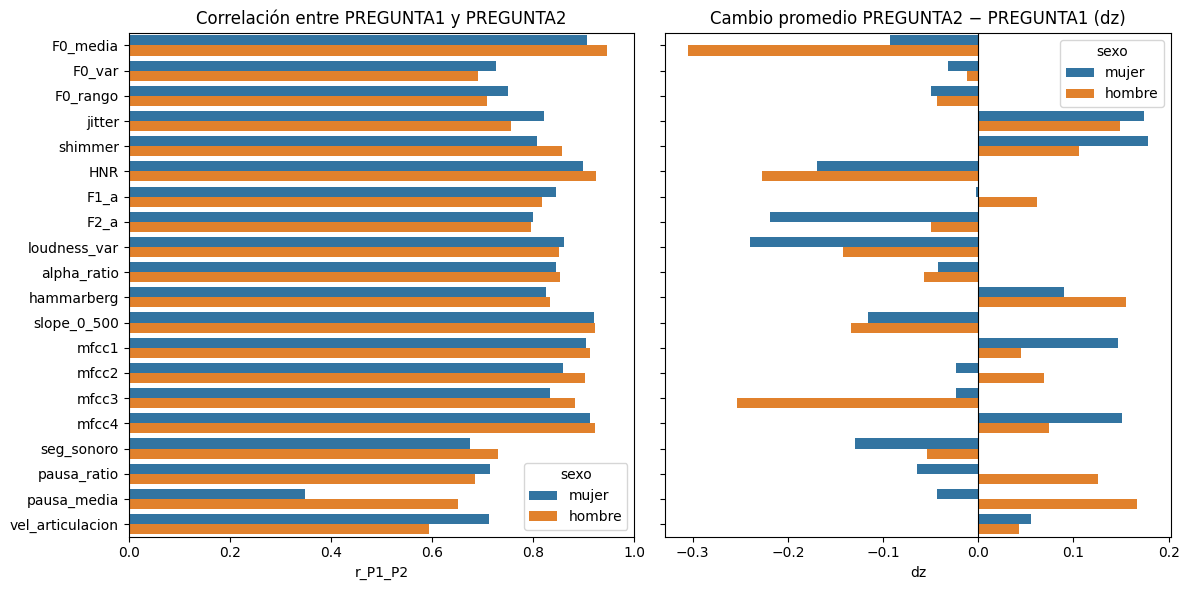

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
sns.barplot(data=cambio, y="feature", x="r_P1_P2", hue="sexo", order=NOMBRES, ax=ax[0])
ax[0].set_title("Correlación entre PREGUNTA1 y PREGUNTA2"); ax[0].set_xlim(0, 1); ax[0].set_ylabel("")
sns.barplot(data=cambio, y="feature", x="dz", hue="sexo", order=NOMBRES, ax=ax[1])
ax[1].axvline(0, color="black", lw=0.8); ax[1].set_title("Cambio promedio PREGUNTA2 − PREGUNTA1 (dz)")
plt.tight_layout(); plt.show()

## 7. d de Cohen entre casos y no casos

d = (media casos − media no casos) / DE combinada. Descriptivo.

dep · mujer: |d| ≥ 0,2 en 3 de 60 (por conjunto: {'PREGUNTA1': 1, 'PREGUNTA2': 1, 'DELTA': 1}) | mayor: vel_articulacion en PREGUNTA2, d = -0.30
ans · mujer: |d| ≥ 0,2 en 3 de 60 (por conjunto: {'PREGUNTA1': 0, 'PREGUNTA2': 0, 'DELTA': 3}) | mayor: pausa_ratio en DELTA, d = -0.32


dep · hombre: |d| ≥ 0,2 en 18 de 60 (por conjunto: {'PREGUNTA1': 2, 'PREGUNTA2': 6, 'DELTA': 10}) | mayor: mfcc2 en DELTA, d = -0.36
ans · hombre: |d| ≥ 0,2 en 21 de 60 (por conjunto: {'PREGUNTA1': 2, 'PREGUNTA2': 10, 'DELTA': 9}) | mayor: vel_articulacion en DELTA, d = 0.48


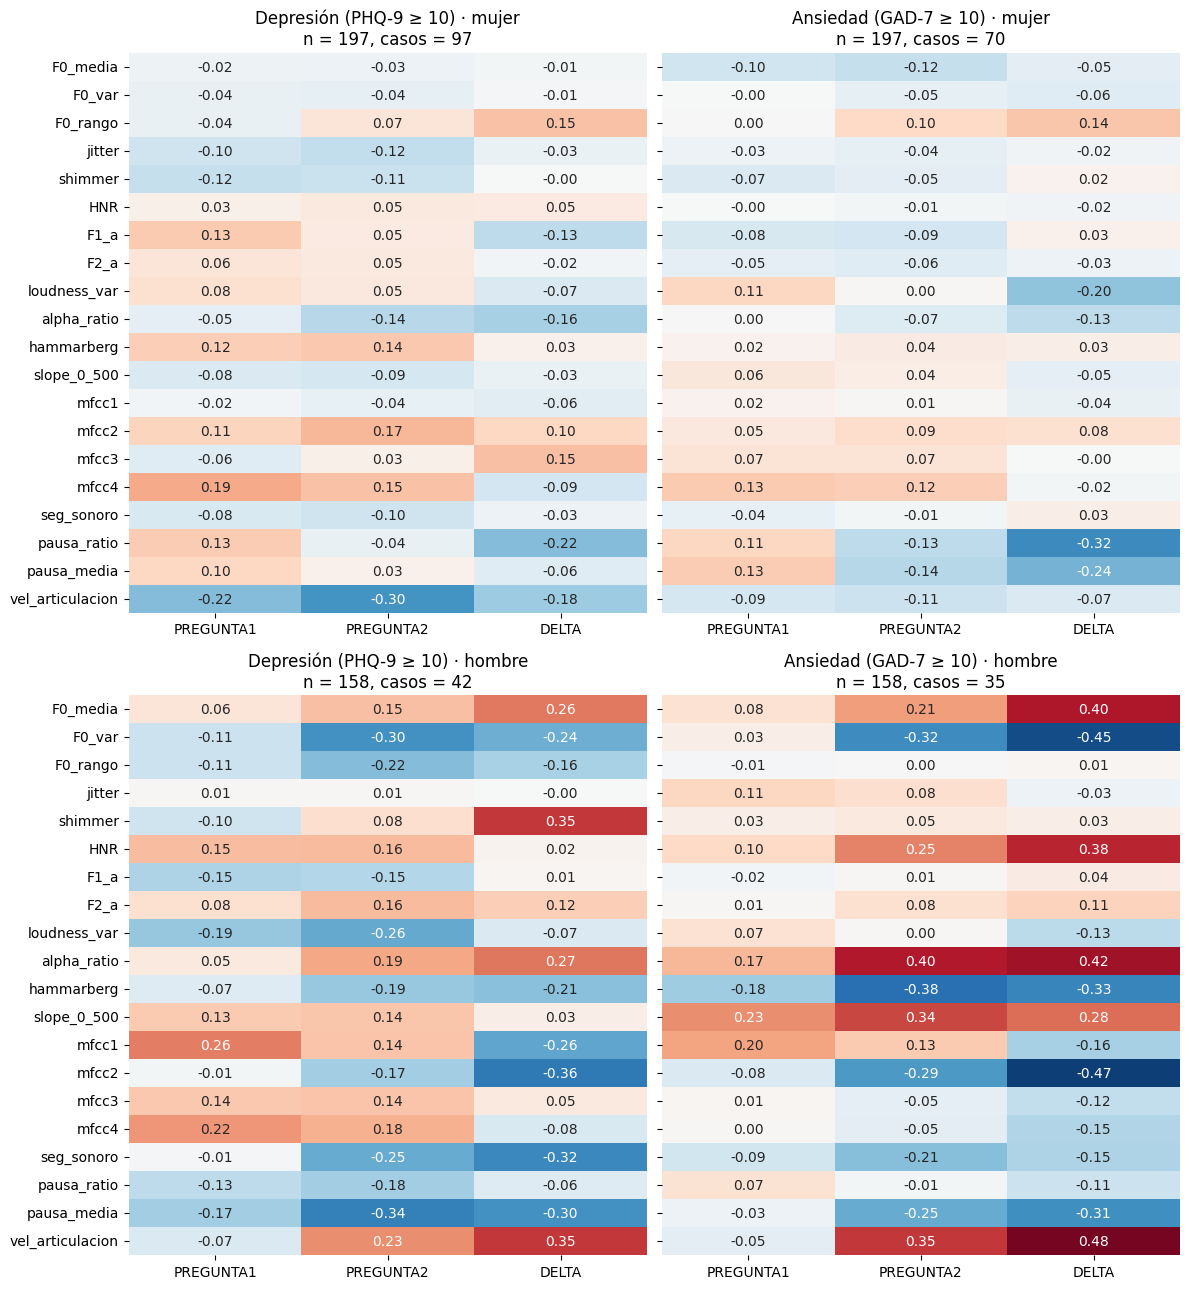

In [15]:
def cohen_d(x, g):
    a, b = x[g == 1].dropna(), x[g == 0].dropna()
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

fig, ax = plt.subplots(2, 2, figsize=(12, 13), sharey=True)
for i, s in enumerate(SEXOS.values()):
    g = datos[datos["sexo"] == s]
    for j, (obj, nombre) in enumerate(OBJETIVOS.items()):
        d = pd.DataFrame({c: [cohen_d(g[f"{f}__{c}"], g[obj]) for f in FEATURES] for c in CONJUNTOS}, index=NOMBRES)
        sns.heatmap(d, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, ax=ax[i, j], cbar=False)
        ax[i, j].set_title(f"{nombre} · {s}\nn = {len(g)}, casos = {g[obj].sum()}")
        mayor = d.abs().stack().idxmax()
        print(f"{obj} · {s}: |d| ≥ 0,2 en {int((d.abs() >= 0.2).values.sum())} de {d.size} "
              f"(por conjunto: {(d.abs() >= 0.2).sum().to_dict()}) | mayor: {mayor[0]} en {mayor[1]}, d = {d.loc[mayor]:.2f}")
plt.tight_layout(); plt.show()

## 8. Correlación entre features

Spearman por sexo, en niveles y en DELTA.

mujer · niveles: pares con |rho| ≥ 0,7: 5 → {'alpha_ratio – hammarberg': -0.91, 'pausa_ratio – pausa_media': 0.8, 'alpha_ratio – mfcc2': -0.78, 'F0_var – jitter': 0.77, 'jitter – shimmer': 0.7}
mujer · DELTA: pares con |rho| ≥ 0,7: 2 → {'alpha_ratio – hammarberg': -0.84, 'alpha_ratio – mfcc2': -0.81}
hombre · niveles: pares con |rho| ≥ 0,7: 6 → {'alpha_ratio – hammarberg': -0.93, 'pausa_ratio – pausa_media': 0.82, 'alpha_ratio – mfcc2': -0.81, 'F0_media – HNR': 0.81, 'shimmer – HNR': -0.76, 'hammarberg – mfcc2': 0.71}
hombre · DELTA: pares con |rho| ≥ 0,7: 2 → {'alpha_ratio – hammarberg': -0.86, 'pausa_ratio – pausa_media': 0.72}


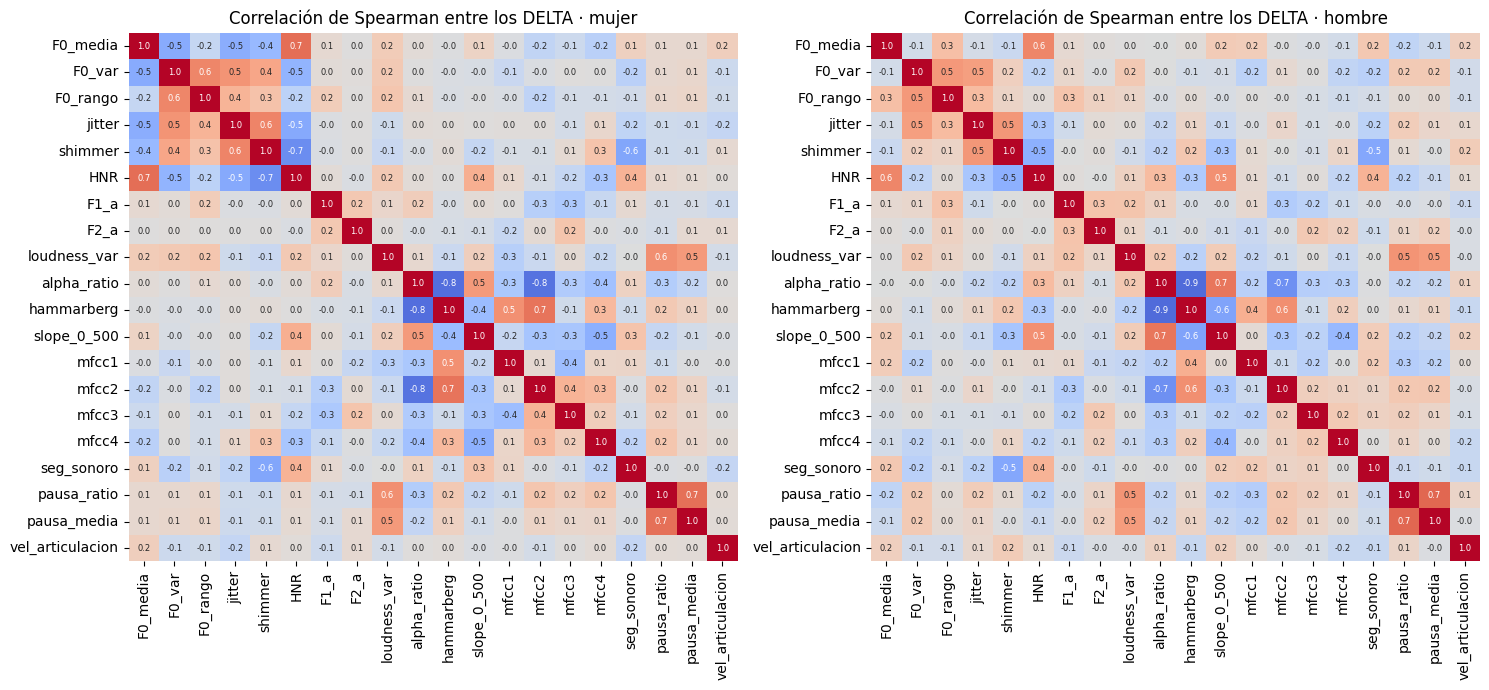

In [16]:
tratado_largo = pd.concat([datos[["sexo"] + [f"{f}__{t}" for f in FEATURES]].set_axis(["sexo"] + NOMBRES, axis=1) for t in TAREAS])
deltas = datos[["sexo"] + [f"{f}__DELTA" for f in FEATURES]].set_axis(["sexo"] + NOMBRES, axis=1)

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
for a, s in zip(ax, SEXOS.values()):
    for nombre, tabla in [("niveles", tratado_largo), ("DELTA", deltas)]:
        corr = tabla.loc[tabla["sexo"] == s, NOMBRES].corr(method="spearman")
        pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
        fuertes = pares[pares.abs() >= 0.7].sort_values(key=abs, ascending=False).round(2)
        print(f"{s} · {nombre}: pares con |rho| ≥ 0,7: {len(fuertes)} → {dict(zip([' – '.join(i) for i in fuertes.index], fuertes.values))}")
    sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 6}, ax=a, cbar=False)
    a.set_title(f"Correlación de Spearman entre los DELTA · {s}")
plt.tight_layout(); plt.show()

## 9. Tasa de muestreo

Media z por tasa (dentro de cada sexo) en PREGUNTA1 y en DELTA; solo tasas con ≥ 10 sujetos.

PREGUNTA2 se asume que se graba en la misma tasa que PREGUNTA1, por eso no existe tabla

PREGUNTA1: media de |z| = 0.224 | máximo |z| = 0.77 | features con algún |z| ≥ 0,3: 11 de 20
DELTA: media de |z| = 0.125 | máximo |z| = 0.40 | features con algún |z| ≥ 0,3: 2 de 20


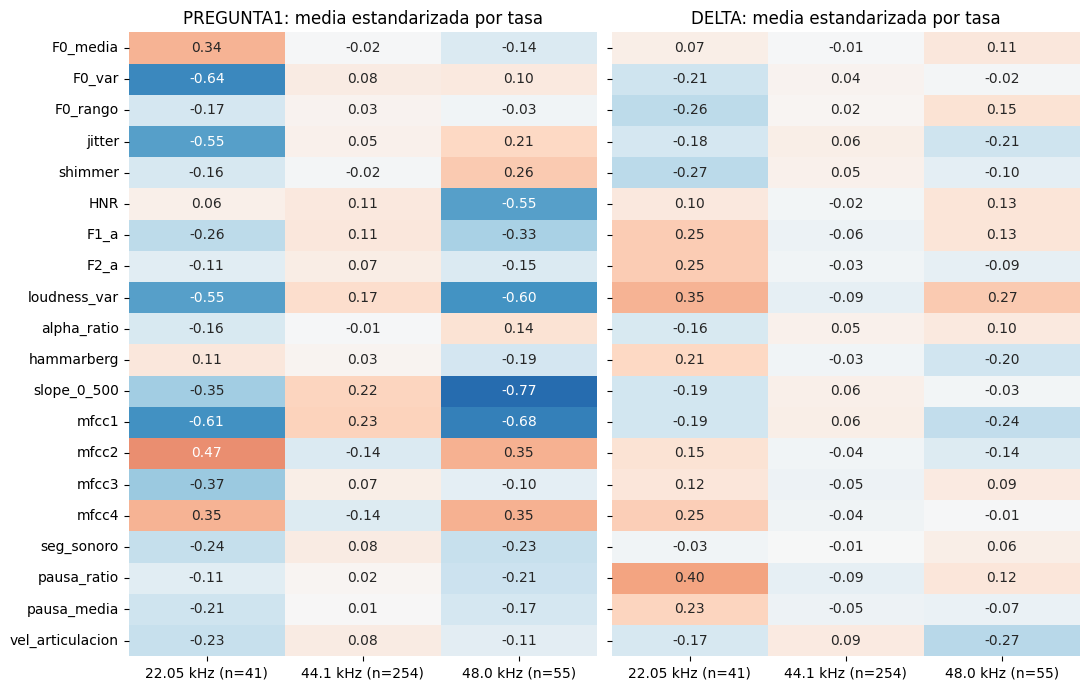

Prevalencia según sexo y tasa de muestreo (solo grupos con 10 sujetos o más):


dep          ans      
                         mean count   mean count
sexo   tasa__PREGUNTA1                          
hombre 22050.0          0.208    24  0.208    24
       44100.0          0.269   108  0.213   108
       48000.0          0.348    23  0.304    23
mujer  22050.0          0.353    17  0.294    17
       44100.0          0.500   146  0.377   146
       48000.0          0.531    32  0.312    32

Sujetos en grupos con menos de 10 (no se muestran): 5


In [17]:
cols = [f"{f}__{c}" for f in FEATURES for c in ["PREGUNTA1", "DELTA"]]
z = datos.groupby("sexo")[cols].transform(lambda v: (v - v.mean()) / v.std())
z["tasa"] = (datos["tasa__PREGUNTA1"] / 1000).round(2).astype(str) + " kHz"
conteo = z["tasa"].value_counts()
grandes = sorted(conteo[conteo >= 10].index)

fig, ax = plt.subplots(1, 2, figsize=(11, 7), sharey=True)
for a, c in zip(ax, ["PREGUNTA1", "DELTA"]):
    m = z[z["tasa"].isin(grandes)].groupby("tasa")[[f"{f}__{c}" for f in FEATURES]].mean().T
    m.index = NOMBRES
    m.columns = [f"{t} (n={conteo[t]})" for t in m.columns]
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=a, cbar=False)
    a.set_title(f"{c}: media estandarizada por tasa")
    print(f"{c}: media de |z| = {m.abs().values.mean():.3f} | máximo |z| = {m.abs().values.max():.2f} | features con algún |z| ≥ 0,3: {int((m.abs() >= 0.3).any(axis=1).sum())} de {len(m)}")
plt.tight_layout(); plt.show()

print("Prevalencia según sexo y tasa de muestreo (solo grupos con 10 sujetos o más):")
grupos = datos.groupby(["sexo", "tasa__PREGUNTA1"])[["dep", "ans"]].agg(["mean", "count"])
display(grupos[grupos[("dep", "count")] >= 10].round(3))
print(f"Sujetos en grupos con menos de 10 (no se muestran): {int(grupos.loc[grupos[('dep', 'count')] < 10, ('dep', 'count')].sum())}")

## 10. Guardar

In [18]:
datos.to_csv(SALIDAS / "desarrollo.csv", index=False)
limites.to_csv(SALIDAS / "limites_outliers.csv", index=False)
print(f"Guardado: {SALIDAS / 'desarrollo.csv'} | {datos.shape[0]} sujetos × {datos.shape[1]} columnas")
print(f"Guardado: {SALIDAS / 'limites_outliers.csv'} | {len(limites)} límites (sexo × columna), tratamiento = {TRATAMIENTO}")
print("Faltantes por conjunto (suma sobre las 20 features):",
      {c: int(datos[[f'{f}__{c}' for f in FEATURES]].isna().values.sum()) for c in CONJUNTOS})

Guardado: outputs\desarrollo.csv | 355 sujetos × 72 columnas
Guardado: outputs\limites_outliers.csv | 80 límites (sexo × columna), tratamiento = recortar
Faltantes por conjunto (suma sobre las 20 features): {'PREGUNTA1': 5, 'PREGUNTA2': 6, 'DELTA': 9}


## Lectura de resultados

**Muestra**: 355 sujetos (197 mujeres, 158 hombres; 1 con `SEXO` = 3 excluido). Faltan F1/F2 en 2 audios por tarea y `vel_articulacion` en 3. Todos tienen la misma tasa en ambas tareas.

**Prevalencias**
- Mujeres: depresión 97 (0,492), ansiedad 70 (0,355), ambas 64.
- Hombres: depresión 42 (0,266), ansiedad 35 (0,222), ambas 29. Con tan pocos casos, `03` no parte la muestra en pliegues.

**Valores extremos**
- Recortados: 153 de 7869 valores en mujeres (1,9 %) y 154 de 6320 en hombres (2,4 %); 68 mujeres y 65 hombres con al menos uno.
- Mayor |z|: `vel_articulacion` 11,4 → 5,2; shimmer 9,6 → 3,3; `F0_rango` 8,4 → 4,6.
- `vel_articulacion`: los 11 valores > 12 vocales/s quedan en 12.
- `pausa_media` conserva valores de hasta 10,8 s (~11 DE). Afecta a logística, SVM y MLP, no a los árboles.

**DELTA**
- r entre tareas: mediana 0,83 (mujeres) y 0,84 (hombres). ≥ 0,90 en F0 media, pendiente 0–500, MFCC1, MFCC4 y HNR; las más bajas, `pausa_media` (0,35 y 0,65) y `vel_articulacion` (0,71 y 0,59).
- Cambio medio chico: |dz| ≤ 0,24 en mujeres y ≤ 0,30 en hombres. q_BH < 0,05: `loudness_var` y F2 en mujeres; F0 media, MFCC3 y HNR en hombres.

**Casos frente a no casos**
- Mujeres: |d| ≥ 0,2 en 3 de 60 por desenlace.
- Hombres: 18 (depresión) y 21 (ansiedad) de 60; por azar se esperan 16–18. Mayor: `vel_articulacion` en DELTA, ansiedad (d = 0,48).

**Correlación entre features**: alpha ratio–Hammarberg (≈ −0,92), `pausa_ratio`–`pausa_media` (≈ 0,81), alpha ratio–MFCC2 (≈ −0,80). En DELTA, 2 pares con |ρ| ≥ 0,7 por sexo.

**Tasa de muestreo**: media de |z| de 0,224 en PREGUNTA1 y 0,125 en DELTA; el DELTA depende menos del equipo. La prevalencia de depresión varía con la tasa (0,35–0,53 en mujeres; 0,21–0,35 en hombres).

**Guardado**: 355 sujetos × 72 columnas; faltantes 5 (PREGUNTA1), 6 (PREGUNTA2) y 9 (DELTA).